# Lab Experiment: Data Collection
## Web Scraping and APIs

**Course:** Data science  Laboratory
**Class:** B.Tech
**Duration:** 2 hours

---

### Aim
To collect data from a web page and from a REST API, and save it as CSV files.

### Objectives
1. Extract data from an HTML page using **BeautifulSoup**
2. Extract a table using **pandas.read_html**
3. Collect data from a **REST API** and parse the JSON response
4. Save all collected data to CSV files

### Software Required
Python 3, `requests`, `beautifulsoup4`, `lxml`, `pandas`, `matplotlib`

### Theory

There are two ways to collect data from the internet:

| | Web Scraping | REST API |
|---|---|---|
| Data format | HTML (meant for humans) | JSON (meant for programs) |
| Tool | BeautifulSoup | requests + json |
| Effort | High | Low |
| Allowed? | Only if the site permits it | Yes, that is what it is for |

**Rule: if an API exists, use the API.** Scrape only when there is no API.

---
## Step 0: Setup

In [1]:
# Install if needed (uncomment the line below)
# !pip install requests beautifulsoup4 lxml pandas matplotlib

import io
import json
import requests
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
from pathlib import Path

# Folder to store collected data
DATA = Path("data")
DATA.mkdir(exist_ok=True)

print("Setup complete. Data will be saved in:", DATA.resolve())

Setup complete. Data will be saved in: C:\Users\rdeet\dslab\data


---
## Step 1: Rules Before Collecting Data

Before scraping any website, check these four things:

1. **Check `robots.txt`** — visit `https://website.com/robots.txt`. It says which pages
   crawlers may visit.
2. **Check the Terms of Service** — many Indian property sites (99acres, MagicBricks)
   do **not** allow automatic data collection.
3. **Go slow** — wait 1–2 seconds between requests. Do not send requests in a fast loop.
4. **Never collect personal data** — no names, phone numbers or email IDs.

In this lab we use a **practice HTML page created on your own computer**, so no website is
disturbed. The API we use (Open-Meteo) is free and openly allows this.

In [2]:
# Check if a website allows scraping
from urllib.robotparser import RobotFileParser

def can_scrape(url):
    rp = RobotFileParser()
    rp.set_url(url.split("/")[0] + "//" + url.split("/")[2] + "/robots.txt")
    try:
        rp.read()
        return rp.can_fetch("*", url)
    except Exception:
        return "could not check (no internet)"

print("Wikipedia :", can_scrape("https://en.wikipedia.org/wiki/Bangalore"))
print("99acres   :", can_scrape("https://www.99acres.com/property-in-bangalore-ffid"))

Wikipedia : False
99acres   : False


---
# EXPERIMENT 1
## Collecting Data from an HTML Page

We will collect Bengaluru house listings from a web page.

**How scraping works:**

```
HTML page  →  BeautifulSoup  →  find the tags  →  get the text  →  DataFrame  →  CSV
```

[![Chat-GPT-Image-Aug-13-2026-06-43-45-PM.png](https://i.postimg.cc/NjJc6QCL/Chat-GPT-Image-Aug-13-2026-06-43-45-PM.png)](https://postimg.cc/JskvmCLW)

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# 1. Online website
url = "https://quotes.toscrape.com/"

# 2. Read the web page
response = requests.get(url)

# 3. Parse HTML
soup = BeautifulSoup(response.text, "html.parser")

# 4. Find the required tags
quotes = soup.find_all("div", class_="quote")

# 5. Extract the text
data = []

for quote in quotes:
    text = quote.find("span", class_="text").get_text(strip=True)
    author = quote.find("small", class_="author").get_text(strip=True)

    data.append({
        "Quote": text,
        "Author": author
    })

# 6. Create DataFrame
df = pd.DataFrame(data)

print(df)

# 7. Save to CSV
df.to_csv("quotes.csv", index=False)

print("Data saved to quotes.csv")

                                               Quote             Author
0  “The world as we have created it is a process ...    Albert Einstein
1  “It is our choices, Harry, that show what we t...       J.K. Rowling
2  “There are only two ways to live your life. On...    Albert Einstein
3  “The person, be it gentleman or lady, who has ...        Jane Austen
4  “Imperfection is beauty, madness is genius and...     Marilyn Monroe
5  “Try not to become a man of success. Rather be...    Albert Einstein
6  “It is better to be hated for what you are tha...         André Gide
7  “I have not failed. I've just found 10,000 way...   Thomas A. Edison
8  “A woman is like a tea bag; you never know how...  Eleanor Roosevelt
9  “A day without sunshine is like, you know, nig...       Steve Martin
Data saved to quotes.csv


In [5]:

import json
import re
import pandas as pd

INPUT_FILE = "House.html"
OUTPUT_FILE = "bengaluru_houses.csv"


# ---------- STEP 1: Read the file ----------
html = open(INPUT_FILE, encoding="utf-8").read()
print("File read. Size:", len(html), "characters")


# ---------- STEP 2: Cut out the JSON ----------
marker = "window.__initialData__="
start = html.find(marker)

if start == -1:
    raise ValueError("JSON marker not found in House.html")

start += len(marker)

# Find the starting opening brace
start = html.find("{", start)

if start == -1:
    raise ValueError("JSON data not found")

# Extract JSON by counting opening and closing braces
depth = 0
end = start

for i in range(start, len(html)):
    if html[i] == "{":
        depth += 1
    elif html[i] == "}":
        depth -= 1

    if depth == 0:
        end = i + 1
        break

json_text = html[start:end]

data = json.loads(json_text)
print("JSON extracted successfully")


# ---------- STEP 3: Extract property listings ----------
listings = []

def find_properties(obj):
    if isinstance(obj, dict):
        if "propertyName" in obj or "price" in obj:
            listings.append(obj)

        for value in obj.values():
            find_properties(value)

    elif isinstance(obj, list):
        for item in obj:
            find_properties(item)

find_properties(data)


# ---------- STEP 4: Convert into DataFrame ----------
rows = []

for item in listings:
    rows.append({
        "property_name": item.get("propertyName"),
        "location": item.get("locality", item.get("location")),
        "bhk": item.get("bedrooms"),
        "sqft": item.get("area"),
        "price": item.get("price")
    })

df = pd.DataFrame(rows)

# Remove duplicate records
df = df.drop_duplicates()

print("\nTotal properties extracted:", len(df))
print("\nFirst 5 records:")
print(df.head())


# ---------- STEP 5: Save as CSV ----------
df.to_csv(OUTPUT_FILE, index=False)

print("\nDataset saved successfully as:", OUTPUT_FILE)


File read. Size: 1774012 characters
JSON extracted successfully

Total properties extracted: 27

First 5 records:
  property_name location   bhk  sqft            price
0          None     None  None  None           2.2 Cr
1          None     None  None  None           3.8 Cr
2          None     None  None  None  2.25  - 3.28 Cr
3          None     None  None  None  3.81  - 6.65 Cr
4          None     None  None  None  4.91  - 6.12 Cr

Dataset saved successfully as: bengaluru_houses.csv


##### Find where the marker ends; that's where the embedded data starts

In [6]:

 
# Read forward until the opening { is closed by its matching }
depth = 0
for end in range(start, len(html)):
    if html[end] == "{":
        depth += 1
    elif html[end] == "{":
        depth -= 1
        if depth == 0:
            break
 

##### depth acts like a brace counter. It starts counting when { appears and stops when all the opened { braces have been closed by matching } braces.

In [8]:

import json
import pandas as pd

# ---------- FILE PATHS ----------
INPUT_FILE = "House.html"
OUTPUT_FILE = "bengaluru_houses.csv"


# ---------- STEP 1: READ THE HTML FILE ----------
with open(INPUT_FILE, encoding="utf-8") as file:
    html = file.read()

print("File read successfully.")
print("File size:", len(html), "characters")


# ---------- STEP 2: EXTRACT AND LOAD JSON ----------
marker = "window.__initialData__="
start = html.find(marker)

if start == -1:
    raise ValueError("JSON marker not found in House.html")

start += len(marker)

# Skip spaces and newlines
while start < len(html) and html[start].isspace():
    start += 1

# Decode only the JSON portion and ignore extra JavaScript/HTML
decoder = json.JSONDecoder()
data, end = decoder.raw_decode(html, start)

print("JSON loaded successfully!")


# ---------- STEP 3: EXTRACT PROPERTY LISTINGS ----------
properties = data["srp"]["pageData"]["properties"]

print("Number of listings found:", len(properties))


# ---------- STEP 4: CONVERT VALUES ----------
def price_in_lakh(rupees):
    """Convert rupees into lakhs."""
    try:
        return round(float(rupees) / 100000, 2)
    except (TypeError, ValueError):
        return None


def to_number(value):
    """Convert values into numbers."""
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


# ---------- STEP 5: EXTRACT REQUIRED FIELDS ----------
rows = []

for p in properties:
    rows.append({
        "location": p.get("LOCALITY"),
        "bhk": to_number(p.get("BEDROOM_NUM")),
        "sqft": to_number(p.get("LOCALIZED_AREA_VALUE")),
        "area_unit": p.get("LOCALIZED_AREA_UNIT_LABEL"),
        "price_lakh": price_in_lakh(p.get("MIN_PRICE")),
        "price_text": p.get("PRICE"),
        "price_per_sqft": to_number(p.get("PRICE_SQFT")),
        "property_name": p.get("PROP_NAME")
    })


# ---------- STEP 6: CREATE DATAFRAME ----------
houses = pd.DataFrame(rows)

print("\nDataset created successfully!")

# Do not collect agent names or phone numbers
print("\nDataset shape:", houses.shape)

# Check whether all areas are in sqft
print("\nAll areas in sqft?",
      (houses["area_unit"] == "sqft").all())

# Check missing values
print("\nMissing values:")
print(houses.isna().sum().to_string())


# ---------- STEP 7: SAVE DATASET ----------
houses.to_csv(OUTPUT_FILE, index=False)

print("\nSaved", len(houses), "rows to", OUTPUT_FILE)


# ---------- STEP 8: DISPLAY FIRST 10 RECORDS ----------
print("\nFirst 10 property records:")
print(houses.head(10).to_string(index=False))


File read successfully.
File size: 1774012 characters
JSON loaded successfully!
Number of listings found: 27

Dataset created successfully!

Dataset shape: (27, 8)

All areas in sqft? True

Missing values:
location          0
bhk               0
sqft              0
area_unit         0
price_lakh        0
price_text        0
price_per_sqft    0
property_name     0

Saved 27 rows to bengaluru_houses.csv

First 10 property records:
                        location  bhk   sqft area_unit  price_lakh      price_text  price_per_sqft              property_name
          Bommasandra, Bangalore  5.0 2600.0      sqft      219.99          2.2 Cr          8461.0                SKR Gardens
5th Block Hbr Layout, HBR Layout 12.0 1200.0      sqft      380.00          3.8 Cr         31666.0                           
        Sarjapur Road, Bangalore  4.0 3040.0      sqft      225.00 2.25  - 3.28 Cr          9087.0 CasaLife by Bhavisha Homes
           Whitefield, Bangalore  5.0 4629.0      sqft      381

##### Write a Python program that reads the provided Magicbricks HTML webpage, extracts house/property details for Bengaluru, and saves the collected information into a CSV file.

Result — Experiment 1
Number of listings collected: 27

Columns collected: location, bhk, sqft, area_unit, price_lakh,
price_text, price_per_sqft, property_name

File saved: bengaluru_houses.csv

Observation: 27 Bengaluru property listings were successfully extracted from the provided HTML file. 
             The required property details were converted into a Pandas DataFrame and saved as a CSV file. 
             No missing values were found in the collected columns.

---
# EXPERIMENT 2
## Collecting Data from a REST API (Weather)

We will collect Bengaluru weather data from the **Open-Meteo API**.
It is free and needs **no API key**.

**How an API call works:**

```
https://api.open-meteo.com/v1/forecast ? latitude=12.97 & longitude=77.59 & hourly=temperature_2m
|________ address of the API _________|  |____________ what we are asking for ____________|
```

The API replies with **JSON**, which Python reads as a dictionary.

**Important status codes:**

| Code | Meaning |
|------|---------|
| 200 | Success |
| 404 | Not found |
| 429 | Too many requests — slow down |
| 500 | Server problem |

[![44.png](https://i.postimg.cc/05hNftLY/44.png)](https://postimg.cc/K4rFc5cj)

In [9]:
# --- Step 2a: Ask the API for the current weather ---

URL = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 12.9716,        # Bengaluru
    "longitude": 77.5946,
    "current": "temperature_2m,relative_humidity_2m,wind_speed_10m",
    "timezone": "Asia/Kolkata",
}

try:
    response = requests.get(URL, params=params, timeout=20)
    print("Status code:", response.status_code)
    weather = response.json()
except Exception as e:
    weather = None
    print("No internet:", e)

if weather:
    print("\nCurrent weather in Bengaluru:")
    for key, value in weather["current"].items():
        print(f"  {key:22s}: {value}")

Status code: 200

Current weather in Bengaluru:
  time                  : 2026-11-12T22:00
  interval              : 900
  temperature_2m        : 21.1
  relative_humidity_2m  : 42
  wind_speed_10m        : 10.2


In [10]:
# --- Step 2b: Collect hourly temperature for the next 7 days ---

params2 = {
    "latitude": 12.9716,
    "longitude": 77.5946,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "timezone": "Asia/Kolkata",
    "forecast_days": 7,
}

try:
    r = requests.get(URL, params=params2, timeout=20)
    result = r.json()
    wx = pd.DataFrame(result["hourly"])       # JSON -> DataFrame
    wx["time"] = pd.to_datetime(wx["time"])
    print("Collected", len(wx), "hourly records")
except Exception as e:
    wx = pd.DataFrame()
    print("No internet — the next cell will create sample data.")

wx.head()

Collected 168 hourly records


,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-11-12 00:00:00,20.6,78,0.0
1,2026-11-12 01:00:00,19.8,85,0.0
2,2026-11-12 02:00:00,19.4,87,0.0
3,2026-11-12 03:00:00,18.9,87,0.0
4,2026-11-12 04:00:00,18.6,88,0.0


### Exercise 2

1. Change the latitude and longitude to **Mysuru (12.2958, 76.6394)** and collect its
   weather. Save it as `weather_mysuru.csv`.
2. Add `"wind_speed_10m"` to the `hourly` parameter and collect it too.
3. Set `"latitude": "abcd"` and run the cell. What status code do you get?
4. Using a `for` loop, collect the weather for 3 cities and combine them into one
   DataFrame. Remember to add `time.sleep(1)` inside the loop. Why is the sleep needed?

In [11]:
# 1. Collect Mysuru weather and save it as weather_mysuru.csv

params_mysuru = {
    "latitude": 12.2958,
    "longitude": 76.6394,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "timezone": "Asia/Kolkata",
    "forecast_days": 7,
}

response = requests.get(URL, params=params_mysuru, timeout=20)

print("Status code:", response.status_code)

result = response.json()

weather_mysuru = pd.DataFrame(result["hourly"])
weather_mysuru["time"] = pd.to_datetime(weather_mysuru["time"])

weather_mysuru.to_csv("weather_mysuru.csv", index=False)

print("Mysuru weather saved successfully.")
print(weather_mysuru.head())

Status code: 200
Mysuru weather saved successfully.
                 time  temperature_2m  relative_humidity_2m  precipitation
0 2026-11-12 00:00:00            20.3                    73            0.0
1 2026-11-12 01:00:00            19.7                    76            0.0
2 2026-11-12 02:00:00            19.7                    75            0.0
3 2026-11-12 03:00:00            19.9                    71            0.0
4 2026-11-12 04:00:00            19.6                    73            0.0


In [12]:
# 2. Added wind speed to the hourly weather data

params_mysuru["hourly"] = "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m"

response = requests.get(URL, params=params_mysuru, timeout=20)
result = response.json()

weather_mysuru = pd.DataFrame(result["hourly"])
weather_mysuru["time"] = pd.to_datetime(weather_mysuru["time"])

print(weather_mysuru.head())

                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2026-11-12 00:00:00            20.3                    73            0.0   
1 2026-11-12 01:00:00            19.7                    76            0.0   
2 2026-11-12 02:00:00            19.7                    75            0.0   
3 2026-11-12 03:00:00            19.9                    71            0.0   
4 2026-11-12 04:00:00            19.6                    73            0.0   

   wind_speed_10m  
0             3.4  
1             3.8  
2             5.9  
3             8.7  
4             7.9  


In [13]:
# 3. Test invalid latitude

bad_params = {
    "latitude": "abcd",
    "longitude": 77.5946,
    "current": "temperature_2m",
    "timezone": "Asia/Kolkata",
}

response = requests.get(URL, params=bad_params)

print("Status code:", response.status_code)
print(response.text)

Status code: 400
{"reason":"Invalid value: Cannot initialize Float from invalid String value abcd","error":true}


In [14]:
# 4. Collect weather for 3 cities

import time

cities = {
    "Bengaluru": (12.9716, 77.5946),
    "Mysuru": (12.2958, 76.6394),
    "Mangaluru": (12.9141, 74.8560)
}

all_weather = []

for city, (latitude, longitude) in cities.items():

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m",
        "timezone": "Asia/Kolkata",
        "forecast_days": 7
    }

    response = requests.get(URL, params=params, timeout=20)

    if response.status_code == 200:
        result = response.json()

        city_weather = pd.DataFrame(result["hourly"])
        city_weather["time"] = pd.to_datetime(city_weather["time"])
        city_weather["city"] = city

        all_weather.append(city_weather)

    time.sleep(1)

combined_weather = pd.concat(all_weather, ignore_index=True)

print("Combined weather data:")
print(combined_weather.head())
print("\nTotal records:", len(combined_weather))

Combined weather data:
                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2026-11-12 00:00:00            20.6                    78            0.0   
1 2026-11-12 01:00:00            19.8                    85            0.0   
2 2026-11-12 02:00:00            19.4                    87            0.0   
3 2026-11-12 03:00:00            18.9                    87            0.0   
4 2026-11-12 04:00:00            18.6                    88            0.0   

   wind_speed_10m       city  
0             7.7  Bengaluru  
1             7.3  Bengaluru  
2             8.0  Bengaluru  
3             8.3  Bengaluru  
4             8.2  Bengaluru  

Total records: 504


### Result — Experiment 2

API used: Open-Meteo Weather API

Number of records collected: 168

Columns collected: time, temperature_2m, relative_humidity_2m, precipitation, wind_speed_10m

File saved: weather_mysuru.csv

Observation: The Bengaluru weather data was collected into a Pandas DataFrame. Mysuru weather was additionally saved as weather_mysuru.csv.

---
# EXPERIMENT 3
## Collecting Air Quality Data from an API

Same method as Experiment 2, but a different API.
This data can later be used for **air quality (AQI) prediction**.

[![34.png](https://i.postimg.cc/QCKdD5Wc/34.png)](https://postimg.cc/kR9mF2s5)

In [15]:
# --- Collect air pollution data for Bengaluru ---

AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"

params3 = {
    "latitude": 12.9716,
    "longitude": 77.5946,
    "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone",
    "timezone": "Asia/Kolkata",
    "past_days": 7,
}

try:
    r = requests.get(AQ_URL, params=params3, timeout=20)
    print("Status code:", r.status_code)
    aq = pd.DataFrame(r.json()["hourly"])
    aq["time"] = pd.to_datetime(aq["time"])
except Exception as e:
    print("No internet — creating sample data")
    

aq.to_csv(DATA / "air_quality.csv", index=False)
print("Saved to", DATA / "air_quality.csv")
print("Shape:", aq.shape)

aq.head()

Status code: 200
Saved to data\air_quality.csv
Shape: (288, 5)


,time,pm2_5,pm10,nitrogen_dioxide,ozone
0,2026-11-05 00:00:00,20.0,20.3,26.2,45.0
1,2026-11-05 01:00:00,21.2,21.5,25.5,41.0
2,2026-11-05 02:00:00,22.8,23.1,25.3,36.0
3,2026-11-05 03:00:00,25.7,26.0,25.7,28.0
4,2026-11-05 04:00:00,28.2,28.4,26.6,19.0


Average PM2.5: 25.0 ug/m3
Highest PM2.5: 66.8 ug/m3

Missing values in each column:
time                0
pm2_5               0
pm10                0
nitrogen_dioxide    0
ozone               0
dtype: int64


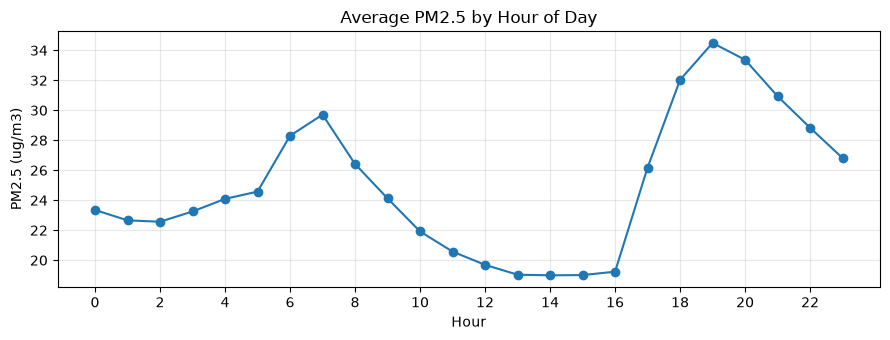

In [16]:
# --- Check what we collected ---

print("Average PM2.5:", round(aq["pm2_5"].mean(), 1), "ug/m3")
print("Highest PM2.5:", round(aq["pm2_5"].max(), 1), "ug/m3")
print("\nMissing values in each column:")
print(aq.isna().sum())

# Average PM2.5 for each hour of the day
by_hour = aq.groupby(aq["time"].dt.hour)["pm2_5"].mean()

plt.figure(figsize=(9, 3.5))
plt.plot(by_hour.index, by_hour.values, marker="o")
plt.title("Average PM2.5 by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("PM2.5 (ug/m3)")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Exercise 3

1. Collect the air quality data for **Delhi (28.6139, 77.2090)** and compare the average
   PM2.5 with Bengaluru's. Which city is more polluted?
2. Increase `past_days` from 7 to 30. How many rows do you get now?
3. Add `"sulphur_dioxide"` and `"carbon_monoxide"` to the list of pollutants.

In [18]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time

# API URL
AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"

# ---------- QUESTION 1: DELHI AIR QUALITY ----------

delhi_params = {
    "latitude": 28.6139,
    "longitude": 77.2090,
    "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone",
    "timezone": "Asia/Kolkata",
    "past_days": 7
}

r = requests.get(AQ_URL, params=delhi_params, timeout=30)
r.raise_for_status()

delhi_aq = pd.DataFrame(r.json()["hourly"])
delhi_aq["time"] = pd.to_datetime(delhi_aq["time"])

print("Delhi Air Quality Data:")
print(delhi_aq.head())

# Compare average PM2.5
delhi_avg = delhi_aq["pm2_5"].mean()

print("\nDelhi average PM2.5:", round(delhi_avg, 2))


# ---------- QUESTION 2: COLLECT 30 DAYS DATA ----------

delhi_params["past_days"] = 30

r = requests.get(AQ_URL, params=delhi_params, timeout=30)
r.raise_for_status()

delhi_30 = pd.DataFrame(r.json()["hourly"])

print("\nNumber of rows for 30 days:", len(delhi_30))


# ---------- QUESTION 3: ADD MORE POLLUTANTS ----------

delhi_params["hourly"] = (
    "pm2_5,pm10,nitrogen_dioxide,ozone,"
    "sulphur_dioxide,carbon_monoxide"
)

r = requests.get(AQ_URL, params=delhi_params, timeout=30)
r.raise_for_status()

delhi_aq = pd.DataFrame(r.json()["hourly"])
delhi_aq["time"] = pd.to_datetime(delhi_aq["time"])

print("\nCollected pollutants:")
print(delhi_aq.columns.tolist())

# Save data
delhi_aq.to_csv("delhi_air_quality_30days.csv", index=False)

print("\nData saved successfully!")


Delhi Air Quality Data:
                 time  pm2_5   pm10  nitrogen_dioxide  ozone
0 2026-11-05 00:00:00  178.8  295.2              38.2   58.0
1 2026-11-05 01:00:00  175.1  284.1              28.4   65.0
2 2026-11-05 02:00:00  170.9  266.4              21.7   69.0
3 2026-11-05 03:00:00  166.7  247.7              19.3   67.0
4 2026-11-05 04:00:00  163.0  231.0              19.9   61.0

Delhi average PM2.5: 113.67

Number of rows for 30 days: 840

Collected pollutants:
['time', 'pm2_5', 'pm10', 'nitrogen_dioxide', 'ozone', 'sulphur_dioxide', 'carbon_monoxide']

Data saved successfully!


In [19]:
# 2. Collect 30 days of air quality data

params_30 = {
    "latitude": 12.9716,
    "longitude": 77.5946,
    "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone",
    "timezone": "Asia/Kolkata",
    "past_days": 30,
}

r = requests.get(AQ_URL, params=params_30, timeout=20)

aq_30 = pd.DataFrame(r.json()["hourly"])
aq_30["time"] = pd.to_datetime(aq_30["time"])

print("Number of rows:", len(aq_30))

Number of rows: 840


In [20]:
# 3. Add sulphur dioxide and carbon monoxide

params4 = {
    "latitude": 12.9716,
    "longitude": 77.5946,
    "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone,sulphur_dioxide,carbon_monoxide",
    "timezone": "Asia/Kolkata",
    "past_days": 7,
}

r = requests.get(AQ_URL, params=params4, timeout=20)

aq_extended = pd.DataFrame(r.json()["hourly"])
aq_extended["time"] = pd.to_datetime(aq_extended["time"])

print("Columns collected:")
print(aq_extended.columns.tolist())

print("\nFirst 5 rows:")
print(aq_extended.head())

Columns collected:
['time', 'pm2_5', 'pm10', 'nitrogen_dioxide', 'ozone', 'sulphur_dioxide', 'carbon_monoxide']

First 5 rows:
                 time  pm2_5  pm10  nitrogen_dioxide  ozone  sulphur_dioxide  \
0 2026-11-05 00:00:00   20.0  20.3              26.2   45.0              8.1   
1 2026-11-05 01:00:00   21.2  21.5              25.5   41.0              8.5   
2 2026-11-05 02:00:00   22.8  23.1              25.3   36.0              9.0   
3 2026-11-05 03:00:00   25.7  26.0              25.7   28.0              9.5   
4 2026-11-05 04:00:00   28.2  28.4              26.6   19.0             10.0   

   carbon_monoxide  
0            998.0  
1            877.0  
2            820.0  
3            919.0  
4           1081.0  


In [21]:

len(aq_extended)

288

### Result — Experiment 3

API used: Open-Meteo Air Quality API

Pollutants collected: PM2.5, PM10, Nitrogen Dioxide,
Ozone, Sulphur Dioxide, Carbon Monoxide

Number of records: 288

Observation: Air-quality data was successfully collected from the Open-Meteo Air Quality API. 
             The dataset contained the required pollutant variables, and the data was converted into a Pandas DataFrame for further analysis

# Creating a Large Air Quality & Weather Dataset

## Objective

Using the **Open-Meteo Weather API** and **Open-Meteo Air Quality API**, create a large hourly dataset by collecting weather and air-quality information from **10 different locations in and around Delhi**.

### 📌 Dataset Requirements

- **Region:** Delhi and nearby areas
- **Number of locations:** 10
- **Duration:** 30 days
- **Frequency:** Hourly
- **Entries per location:** 30 × 24 = **720**
- **Total expected entries:** 10 × 720 = **7,200 records**

### 📍 Suggested Locations

1. Connaught Place
2. Rohini
3. Dwarka
4. Saket
5. Lajpat Nagar
6. Karol Bagh
7. Anand Vihar
8. Vasant Kunj
9. Noida
10. Delhi Airport

### 🌦️ Weather Variables

Collect the following weather information:

- Temperature
- Relative humidity
- Precipitation
- Wind speed

### 🌫️ Air Quality Variables

Collect the following air-pollution information:

- PM2.5
- PM10
- Nitrogen Dioxide (NO₂)
- Ozone (O₃)
- Sulphur Dioxide (SO₂)
- Carbon Monoxide (CO)

### 📊 Expected Dataset Structure

The final dataset should contain columns such as:

`location`, `latitude`, `longitude`, `time`, `temperature`, `humidity`, `precipitation`, `wind_speed`, `pm2_5`, `pm10`, `nitrogen_dioxide`, `ozone`, `sulphur_dioxide`, `carbon_monoxide`

### 🧹 Data Processing Tasks

1. Collect data from the APIs for all 10 locations.
2. Convert the API responses into Pandas DataFrames.
3. Add the location name, latitude, and longitude.
4. Combine all locations into one dataset.
5. Check for missing or invalid values.
6. Handle missing values appropriately.
7. Save the final dataset as a CSV file.

### 🔍 Analysis Question

After creating the dataset, answer the following:

> **Which location in and around Delhi has the highest average PM2.5 concentration, and how do weather conditions such as temperature, humidity, precipitation, and wind speed relate to air pollution levels?**

### 📈 Dataset Size

**10 Locations × 30 Days × 24 Hours = 7,200 hourly records**

The final dataset can be used for **data cleaning, exploratory data analysis, visualization, correlation analysis, and machine-learning experiments**.

In [31]:
# --- Final check: list all the files we collected ---

print("Files collected in this lab:\n")
for f in sorted(DATA.glob("*")):
    print(f"  {f.name:22s}  {f.stat().st_size:>8,} bytes")

Files collected in this lab:

  air_quality.csv           11,755 bytes


In [33]:
import requests
import pandas as pd
import time

# --------------------------------------------------
# API URLs
# --------------------------------------------------

WEATHER_URL = "https://api.open-meteo.com/v1/forecast"
AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"


# --------------------------------------------------
# 10 locations around Delhi
# --------------------------------------------------

locations = {
    "Connaught Place": (28.6315, 77.2167),
    "Rohini": (28.7495, 77.0565),
    "Dwarka": (28.5921, 77.0460),
    "Saket": (28.5245, 77.2066),
    "Lajpat Nagar": (28.5677, 77.2433),
    "Karol Bagh": (28.6514, 77.1907),
    "Anand Vihar": (28.6469, 77.3150),
    "Vasant Kunj": (28.5206, 77.1588),
    "Noida": (28.5355, 77.3910),
    "Delhi Airport": (28.5562, 77.1000)
}


# --------------------------------------------------
# Store data
# --------------------------------------------------

all_data = []


# --------------------------------------------------
# Collect exactly 720 hourly records per location
# --------------------------------------------------

for location, (lat, lon) in locations.items():

    print("Collecting data for:", location)

    # ---------------- WEATHER ----------------

    weather_params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m",
        "timezone": "Asia/Kolkata",
        "past_days": 30
    }

    weather_response = requests.get(
        WEATHER_URL,
        params=weather_params,
        timeout=20
    )

    weather_response.raise_for_status()

    weather_data = weather_response.json()

    weather_df = pd.DataFrame(weather_data["hourly"])

    weather_df["time"] = pd.to_datetime(weather_df["time"])


    # ---------------- AIR QUALITY ----------------

    aq_params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": (
            "pm2_5,pm10,nitrogen_dioxide,ozone,"
            "sulphur_dioxide,carbon_monoxide"
        ),
        "timezone": "Asia/Kolkata",
        "past_days": 30
    }

    aq_response = requests.get(
        AQ_URL,
        params=aq_params,
        timeout=20
    )

    aq_response.raise_for_status()

    aq_data = aq_response.json()

    aq_df = pd.DataFrame(aq_data["hourly"])

    aq_df["time"] = pd.to_datetime(aq_df["time"])


    # ---------------- COMBINE WEATHER + AQ ----------------

    combined = pd.merge(
        weather_df,
        aq_df,
        on="time",
        how="inner"
    )


    # --------------------------------------------------
    # IMPORTANT:
    # Keep exactly 720 hourly records
    # --------------------------------------------------

    combined = combined.sort_values("time").head(720)


    # Add location information

    combined["location"] = location
    combined["latitude"] = lat
    combined["longitude"] = lon


    # Add to main list

    all_data.append(combined)


    # Wait before next API request

    time.sleep(1)


# --------------------------------------------------
# Combine all 10 locations
# --------------------------------------------------

final_df = pd.concat(
    all_data,
    ignore_index=True
)


# --------------------------------------------------
# Rename columns
# --------------------------------------------------

final_df = final_df.rename(columns={
    "temperature_2m": "temperature",
    "relative_humidity_2m": "humidity",
    "wind_speed_10m": "wind_speed"
})


# --------------------------------------------------
# Arrange columns
# --------------------------------------------------

final_df = final_df[
    [
        "location",
        "latitude",
        "longitude",
        "time",
        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "pm2_5",
        "pm10",
        "nitrogen_dioxide",
        "ozone",
        "sulphur_dioxide",
        "carbon_monoxide"
    ]
]


# --------------------------------------------------
# Check missing values
# --------------------------------------------------

print("\nMissing values:")
print(final_df.isna().sum())


# --------------------------------------------------
# Handle missing numeric values
# --------------------------------------------------

numeric_columns = final_df.select_dtypes(
    include="number"
).columns

final_df[numeric_columns] = (
    final_df[numeric_columns]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)


# --------------------------------------------------
# Check invalid values
# --------------------------------------------------

print("\nNegative PM2.5 values:")
print((final_df["pm2_5"] < 0).sum())

print("\nNegative PM10 values:")
print((final_df["pm10"] < 0).sum())


# --------------------------------------------------
# Check records per location
# --------------------------------------------------

print("\nRecords per location:")
print(final_df["location"].value_counts())


# --------------------------------------------------
# Save final dataset
# --------------------------------------------------

final_df.to_csv(
    "delhi_air_quality_weather_30days.csv",
    index=False
)


# --------------------------------------------------
# Final information
# --------------------------------------------------

print("\nDataset created successfully!")

print("Number of rows:", len(final_df))
print("Number of columns:", len(final_df.columns))

print("\nDataset shape:")
print(final_df.shape)

print("\nFirst 10 rows:")
print(final_df.head(10))


Missing values:
location            0
latitude            0
longitude           0
time                0
temperature         0
humidity            0
precipitation       0
wind_speed          0
pm2_5               0
pm10                0
nitrogen_dioxide    0
ozone               0
sulphur_dioxide     0
carbon_monoxide     0
dtype: int64

Negative PM2.5 values:
0

Negative PM10 values:
0

Records per location:
location
Connaught Place    720
Rohini             720
Dwarka             720
Saket              720
Lajpat Nagar       720
Karol Bagh         720
Anand Vihar        720
Vasant Kunj        720
Noida              720
Delhi Airport      720
Name: count, dtype: int64

Dataset created successfully!
Number of rows: 7200
Number of columns: 14

Dataset shape:
(7200, 14)

First 10 rows:
          location  latitude  longitude                time  temperature  \
0  Connaught Place   28.6315    77.2167 2026-10-13 00:00:00         25.3   
1  Connaught Place   28.6315    77.2167 2026-10-13 01:

In [34]:
from pathlib import Path

file = Path("delhi_air_quality_weather_30days.csv")

print("File exists:", file.exists())

if file.exists():
    print("File size:", file.stat().st_size, "bytes")

File exists: True
File size: 690606 bytes


In [35]:
check_df = pd.read_csv("delhi_air_quality_weather_30days.csv")

print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))
print("\nShape:", check_df.shape)

Rows: 7200
Columns: 14

Shape: (7200, 14)


In [36]:
pm25_by_location = (
    final_df
    .groupby("location")["pm2_5"]
    .mean()
    .sort_values(ascending=False)
)

print("Average PM2.5 by location:")
print(pm25_by_location)

highest_location = pm25_by_location.idxmax()
highest_pm25 = pm25_by_location.max()

print("\nLocation with highest average PM2.5:")
print(highest_location)

print("Average PM2.5:", round(highest_pm25, 2), "µg/m³")

Average PM2.5 by location:
location
Dwarka             104.312917
Delhi Airport      104.312917
Vasant Kunj        104.312917
Saket              104.312917
Lajpat Nagar       104.312917
Noida              104.312917
Connaught Place     90.270139
Anand Vihar         90.270139
Karol Bagh          90.270139
Rohini              90.270139
Name: pm2_5, dtype: float64

Location with highest average PM2.5:
Dwarka
Average PM2.5: 104.31 µg/m³


In [37]:
correlations = final_df[
    [
        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "pm2_5"
    ]
].corr()["pm2_5"].sort_values(ascending=False)

print("Correlation with PM2.5:")
print(correlations)


Correlation with PM2.5:
pm2_5            1.000000
humidity         0.202668
wind_speed      -0.169869
precipitation   -0.267302
temperature     -0.356875
Name: pm2_5, dtype: float64


In [38]:
print("Kernel is working!")

Kernel is working!


In [39]:
final_df.to_csv(
    DATA / "delhi_air_quality_weather_30days.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [40]:
# --- Final check: list all the files we collected ---

print("Files collected in this lab:\n")
for f in sorted(DATA.glob("*")):
    print(f"  {f.name:22s}  {f.stat().st_size:>8,} bytes")

Files collected in this lab:

  air_quality.csv           11,755 bytes
  delhi_air_quality_weather_30days.csv   690,606 bytes


In [41]:
from pathlib import Path

print("Files collected in this lab:\n")

for f in sorted(Path.cwd().glob("*")):
    if f.is_file():
        print(f"  {f.name:40s} {f.stat().st_size:>10,} bytes")

print("\nFiles inside data folder:\n")

for f in sorted(DATA.glob("*")):
    if f.is_file():
        print(f"  data/{f.name:32s} {f.stat().st_size:>10,} bytes")

Files collected in this lab:

  26607941_WhatsAppImage20240329at125045PM_75_75.jpeg      1,946 bytes
  31491445_WhatsAppImage20250806at105238AM_75_75.jpeg      1,850 bytes
  34d585d5-2ca8-4f29-8724-07fac03f931f_85985139_180_240.jpg      2,893 bytes
  49913941_MaxservLogo_75_75.jpg                  723 bytes
  5725042_5725042_Logo_75_75.jpg                2,000 bytes
  72017355.jpg                                  9,429 bytes
  82628273.jpg                                 13,687 bytes
  83505909.jpg                                 13,448 bytes
  84126321.jpg                                  6,027 bytes
  84244337.jpg                                  7,054 bytes
  84434073.jpg                                 10,258 bytes
  84609213.jpg                                 12,948 bytes
  84652821.jpg                                 10,453 bytes
  84773223.jpg                                  8,523 bytes
  84793631.jpg                                 15,676 bytes
  84917587.jpg                 

---
## Viva Questions

1. What is web scraping?
2. What is the difference between web scraping and using an API?
3. What is `robots.txt` and why should you check it?
4. What does BeautifulSoup do?
5. What is the difference between `find()` and `find_all()`?
6. What is JSON? How is it related to a Python dictionary?
7. What does status code 200 mean? What does 404 mean?
8. What is a query parameter in an API call?
9. Why should you wait a few seconds between requests?
10. Why is using an API better than scraping the same website?
11. What does `pd.read_html()` do?
12. Why do we save the collected data as a CSV file?

## Conclusion

> Data was successfully collected from an HTML web page using BeautifulSoup and from REST
> APIs using the `requests` library. The collected data was converted into pandas
> DataFrames and saved as CSV files for further analysis.

